# Sticky walls in a capped cylinder — Separation of Variables notebook
This notebook implements the sticky‑walls model using separation of variables (SoV) as the main solver. The finite‑difference Crank–Nicolson (CN) method appears only at the end as a verification tool. The formulation matches SM‑IIIA: Dirichlet propagator in a capped cylinder, harmonic measure via the torsion function, and bulk/adsorbed correlation decomposition.

## Geometry, parameters, and boundary conditions
We consider an axisymmetric capped cylinder:

- Radial coordinate: $\rho \in [0, R]$
- Axial coordinate: $z \in [d, L + d]$, where $d$ is the NV depth
- Geometry: $R = L = 10\,d$

Boundary conditions:

- Dirichlet (absorbing) on $r = R$, $z = d$, and $z = L + d$
- Regularity at the axis $r = 0$: $\partial_r \overline{P}|_{r=0} = 0$

We solve for the averaged propagator with uniform initial condition:
$$
\partial_t \overline{P} = D \nabla^2 \overline{P}, \quad
\overline{P}|_{\partial\Omega} = 0, \quad
\overline{P}(r,z,0) = \frac{1}{|\Omega|},
$$
with $|\Omega| = \pi R^2 L$ and shifted axial coordinate $u = z - d \in [0, L]$.

In [ ]:
import numpy as np
from scipy.special import jn_zeros, j0, j1
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import pandas as pd

# Physical scale and geometry
d = 15.0                 # nm (NV depth)
R = 10.0 * d             # nm
L = 10.0 * d             # nm
d_shift = d              # bottom cap at z = d, top cap at z = L + d

D = 1.0                  # nm^2 / µs (diffusion coefficient)
Omega_vol = np.pi * R**2 * L

# Grids for plotting/integration
Nr, Nz = 256, 256
r = np.linspace(0.0, R, Nr)                      # ρ in [0, R]
z = np.linspace(d_shift, L + d_shift, Nz)        # z in [d, L + d]
dr = r[1] - r[0]
dz = z[1] - z[0]
u = z - d_shift                                  # shifted axial coordinate u in [0, L]

# Time grid
t_diff = (R**2) / D
Nt = 800
t_end = 1.5 * t_diff
times = np.linspace(0.0, t_end, Nt + 1)
dt = times[1] - times[0]

# Integration helpers
def vol_int(f):
    """int Ω f dV with cylindrical measure."""
    return np.sum(f * (2.0 * np.pi * r * dr)[:, None]) * dz

def surf_int_lateral(g_of_z):
    """int lateral g(z) dS = 2π R int g(z) dz."""
    return 2.0 * np.pi * R * np.trapezoid(g_of_z, z)

def surf_int_cap(g_of_r):
    """int cap g(r) dS = 2π int g(r) r dr."""
    return 2.0 * np.pi * np.trapezoid(g_of_r * r, r)

## SoV eigenproblem

Axisymmetric eigenfunctions for the Dirichlet Laplacian in a capped cylinder:

- Radial: $\phi_{r,m}(r) = \frac{1}{R J_1(\gamma_m)} J_0\!\left(\gamma_m \frac{r}{R}\right)$, with $\gamma_m$ the $m$‑th zero of $J_0$
- Axial:  $\phi_{z,n}(u) = \sqrt{\frac{2}{L}} \sin\!\left(\frac{n \pi u}{L}\right)$, $u \in [0, L]$

Eigenvalues:
$$
\lambda_{mn} = \left(\frac{\gamma_m}{R}\right)^2 + \left(\frac{n \pi}{L}\right)^2.
$$

In [2]:
# Mode truncation
M_modes = 50
N_modes = 50

# Zeros of J0 for radial Dirichlet at r = R
gamma = jn_zeros(0, M_modes)

# Axial indices
n_idx = np.arange(1, N_modes + 1)

# Spatial factors on the grid
phi_r = np.array([
    (1.0 / (R * j1(gamma[m]))) * j0(gamma[m] * r / R)
    for m in range(M_modes)
])  # (M, Nr)

phi_z = np.array([
    np.sqrt(2.0 / L) * np.sin(n * np.pi * u / L)
    for n in n_idx
])  # (N, Nz)

# Eigenvalues
lam = (gamma[:, None] / R)**2 + (n_idx[None, :] * np.pi / L)**2

## Modal coefficients for uniform initial condition
For $\overline{P}(\cdot,0) = 1/|\Omega|$, the modal coefficients are:
$$
a_{mn} = \frac{1}{\pi R L} \cdot \frac{\sqrt{2L}}{\gamma_m n \pi} \left[1 - (-1)^n\right],
$$
so only odd $n$ contribute.

In [3]:
coef_pref = (1.0 / (np.pi * R * L)) * (np.sqrt(2.0 * L) / np.pi)
a = np.zeros((M_modes, N_modes))
odd_mask = (n_idx % 2 == 1)
a[:, odd_mask] = coef_pref * 2.0 * (1.0 / gamma[:, None]) * (1.0 / n_idx[None, odd_mask])

## SoV propagator

The averaged propagator is:
$$
\overline{P}(r,z,t) = \sum_{m=1}^M \sum_{n=1}^N a_{mn} \, \phi_{r,m}(r) \, \phi_{z,n}(z) \, e^{-D \lambda_{mn} t}.
$$

In [4]:
# Precompute spatial tensor Φ_mn(r,z)
Phi = np.einsum('mi,nk->mnik', phi_r, phi_z)  # (M, N, Nr, Nz)

def Pbar_sov(t):
    decay = np.exp(-D * lam * t)               # (M, N)
    return np.einsum('mn,mn,mnik->ik', a, decay, Phi)  # (Nr, Nz)

## Flux formulas from SoV

From the SoV expansion we can compute the outward diffusive flux on each absorbing surface.

For a mode $(m,n)$:

- Lateral wall ($r = R$):  
  $\displaystyle \partial_n \phi_{r,m} = \frac{\partial \phi_{r,m}}{\partial r}\bigg|_{r=R} = -\frac{\gamma_m}{R^2}$

- Bottom cap ($z = d$, $u = 0$):  
  $\displaystyle \partial_n \phi_{z,n} = -\frac{\partial \phi_{z,n}}{\partial z}\bigg|_{u=0} = -\sqrt{\frac{2}{L}} \frac{n\pi}{L}$

- Top cap ($z = L+d$, $u = L$):  
  $\displaystyle \partial_n \phi_{z,n} = +\frac{\partial \phi_{z,n}}{\partial z}\bigg|_{u=L} = +\sqrt{\frac{2}{L}} \frac{n\pi}{L} (-1)^n$

The outward flux density is $j(s,t) = -\partial_n \overline{P}(s,t)$.

In [ ]:
# --- Normal derivatives for each mode at the absorbing boundaries ---

# Lateral wall (r = R): outward normal is +r
dphi_r_n_at_R = -gamma / (R**2)  # shape (M,)

# Bottom cap (z = d, u = 0): outward normal is -z
dphi_z_n_bottom = -np.sqrt(2.0 / L) * (n_idx * np.pi / L)  # shape (N,)

# Top cap (z = L + d, u = L): outward normal is +z
dphi_z_n_top = np.sqrt(2.0 / L) * (n_idx * np.pi / L) * ((-1) ** n_idx)  # shape (N,)

# --- Flux density functions j(s,t) = -partial n P(s,t) ---

def j_lateral_sov(t):
    """Outward flux density on the lateral wall as a function of z."""
    decay = np.exp(-D * lam * t)  # (M, N)
    coef = (gamma[:, None] / (R**2)) * a * decay  # (M, N)
    jz = np.einsum('mn,nk->k', coef, phi_z)       # (Nz,)
    return np.clip(jz, 0.0, None)

def j_bottom_sov(t):
    """Outward flux density on the bottom cap as a function of r."""
    decay = np.exp(-D * lam * t)  # (M, N)
    coef_n = (a * decay) * dphi_z_n_bottom[None, :]  # (M, N)
    jr = np.einsum('mn,mi->i', coef_n, phi_r)        # (Nr,)
    return np.clip(jr, 0.0, None)

def j_top_sov(t):
    """Outward flux density on the top cap as a function of r."""
    decay = np.exp(-D * lam * t)  # (M, N)
    coef_n = (a * decay) * dphi_z_n_top[None, :]     # (M, N)
    jr = np.einsum('mn,mi->i', coef_n, phi_r)        # (Nr,)
    return np.clip(jr, 0.0, None)

## Accumulated surface density $\overline{\omega}_t(s)$

We integrate the outward flux over time to get the accumulated surface density:
$$
\overline{\omega}_t(s) = \int_0^t j(s,T)\,dT
$$
for each surface patch.We integrate the outward flux over time to get the accumulated surface density:
$$
\overline{\omega}_t(s) = \int_0^t j(s,T)\,dT
$$
for each surface patch.

In [ ]:
# Final-time accumulated surface density ω_t(s) (if you still want the final profiles)
omega_lat = np.zeros_like(z)
omega_bot = np.zeros_like(r)
omega_top = np.zeros_like(r)

j_lat_prev = j_bot_prev = j_top_prev = None
for i, t in enumerate(times):
    j_lat = j_lateral_sov(t)
    j_bot = j_bottom_sov(t)
    j_top = j_top_sov(t)
    if i > 0:
        omega_lat += 0.5 * (j_lat_prev + j_lat) * dt
        omega_bot += 0.5 * (j_bot_prev + j_bot) * dt
        omega_top += 0.5 * (j_top_prev + j_top) * dt
    j_lat_prev, j_bot_prev, j_top_prev = j_lat, j_bot, j_top

## Harmonic measure via torsion

The harmonic measure $w(s)$ is the $t \to \infty$ limit of $\overline{\omega}_t(s)$.
We compute it from the torsion function $U$ solving:
$$
\nabla^2 U = -1 \quad\text{in }\Omega,\quad U|_{\partial\Omega} = 0
$$
and
$$
w(s) = -\frac{D}{|\Omega|} \,\partial_n U(s)
$$
normalized so that $\int_{\partial\Omega} w(s)\,dS = 1$.

In [ ]:
# Axisymmetric Laplacian with Neumann at r=0 (regularity) and Dirichlet on r=R, z-caps
def build_axisym_laplacian(Nr, Nz, dr, dz, r):
    N = Nr * Nz
    rows, cols, data = [], [], []
    def idx(i,j): return i*Nz + j

    for i in range(Nr):
        for j in range(Nz):
            p = idx(i,j)
            # Caps and outer wall Dirichlet; special row for i=0 (Neumann)
            if i == Nr-1 or j == 0 or j == Nz-1:
                rows.append(p); cols.append(p); data.append(1.0)
                continue
            if i == 0:
                # Reflective (Neumann) at r=0: use mirrored stencil with r=dr
                rp = r[1]  # avoid singularity at 0
                rows += [p,p,p,p]
                cols += [idx(1,j), idx(0,j), idx(0,j-1), idx(0,j+1)]
                data += [1.0/(dr**2) + 1.0/(rp*dr),
                         -2.0/(dr**2) - 2.0/(dz**2) - 1.0/(rp*dr),
                         1.0/(dz**2), 1.0/(dz**2)]
                continue
            # Interior
            ri = r[i]
            rows += [p,p,p,p,p]
            cols += [idx(i,j), idx(i-1,j), idx(i+1,j), idx(i,j-1), idx(i,j+1)]
            data += [
                -2.0/(dr**2) - 2.0/(dz**2) - 1.0/(ri*dr),
                 1.0/(dr**2) + 1.0/(ri*dr),
                 1.0/(dr**2),
                 1.0/(dz**2),
                 1.0/(dz**2),
            ]
    return sp.csr_matrix((data, (rows, cols)), shape=(N, N))

Lmat = build_axisym_laplacian(Nr, Nz, dr, dz, r)
rhs = -np.ones(Nr * Nz)
U = spla.spsolve(Lmat, rhs).reshape(Nr, Nz)

# Outward normal derivatives
dUn_lat = (U[-1, :] - U[-2, :]) / dr   # +r
dUn_bot = -(U[:, 1] - U[:, 0]) / dz    # -z
dUn_top = (U[:, -1] - U[:, -2]) / dz   # +z

# Harmonic measure (normalize to 1)
w_lat = np.clip(-(D / Omega_vol) * dUn_lat, 0.0, None)
w_bot = np.clip(-(D / Omega_vol) * dUn_bot, 0.0, None)
w_top = np.clip(-(D / Omega_vol) * dUn_top, 0.0, None)

W_tot = surf_int_lateral(w_lat) + surf_int_cap(w_bot) + surf_int_cap(w_top)
w_lat /= W_tot; w_bot /= W_tot; w_top /= W_tot

In [ ]:
# --- Spin density and dipolar form factors F^2 (NV axis = z) ---

rho = 1.0  # number density (set your value if you need absolute scale)

# Optional physical prefactor; leave at 1.0 if you normalise correlations
C2_prefactor = 1.0

def F2_geom_rrz(r_grid, z_grid):
    rr2 = (r_grid[:, None]**2) + (z_grid[None, :]**2)
    rr2 = np.maximum(rr2, 1e-30)
    cos2 = (z_grid[None, :]**2) / rr2
    return C2_prefactor * ((1.0 - 3.0*cos2)**2) / (rr2**3)

def F2_geom_surface_r(r_array, z_fixed):
    rr2 = r_array**2 + z_fixed**2
    rr2 = np.maximum(rr2, 1e-30)
    cos2 = (z_fixed**2) / rr2
    return C2_prefactor * ((1.0 - 3.0*cos2)**2) / (rr2**3)

def F2_geom_surface_z(z_array, r_fixed):
    rr2 = r_fixed**2 + z_array**2
    rr2 = np.maximum(rr2, 1e-30)
    cos2 = (z_array**2) / rr2
    return C2_prefactor * ((1.0 - 3.0*cos2)**2) / (rr2**3)

# Volume and surfaces
F2V   = F2_geom_rrz(r, z)                          # (Nr, Nz)
F2_lat = F2_geom_surface_z(z, r_fixed=R)           # z in [d, L+d], r=R
F2_bot = F2_geom_surface_r(r, z_fixed=d_shift)     # r in [0,R], z=d
F2_top = F2_geom_surface_r(r, z_fixed=L+d_shift)   # r in [0,R], z=L+d

# Bulk signal time series (needed for C_total)
def G_bulk_from_P(P):
    return vol_int(F2V * P)

G_bulk_t = np.array([G_bulk_from_P(Pbar_sov(t)) for t in times])
G_bulk_0 = G_bulk_t[0]

# Steady-state adsorbed (harmonic measure)
G_lat_inf = rho * surf_int_lateral(F2_lat * w_lat)
G_bot_inf = rho * surf_int_cap(F2_bot * w_bot)
G_top_inf = rho * surf_int_cap(F2_top * w_top)
G_ads_inf = G_lat_inf + G_bot_inf + G_top_inf

## Correlations

Let $F^2$ be the form factor (set to $1$ here for simplicity).

- Bulk signal:
$$
G_{\mathrm{bulk}}(t) = \int_\Omega F^2_{\mathrm{vol}}\,\overline{P}(t)\,dV
$$

- Adsorbed signal:
$$
G_{\mathrm{ads}}(t) = \rho \int_{\partial\Omega} F^2(s)\,\overline{\omega}_t(s)\,dS
$$

Correlations:
$$
C_{\mathrm{ads}}(t) = 1 - \frac{G_{\mathrm{ads}}(t)}{G_{\mathrm{ads}}(\infty)},\quad
C_{\mathrm{total}}(t) = \frac{G_{\mathrm{bulk}}(t) + G_{\mathrm{ads}}(t)}{G_{\mathrm{bulk}}(0)}
$$

In [ ]:
# --- Time series of adsorbed signals from SoV flux accumulation (with correct surface weights) ---

# Increase modes if caps look too flat (resolution of axial derivative)
M_modes = max(M_modes, 60)
N_modes = max(N_modes, 120)
# Rebuild mode arrays if you changed counts (optional):
# gamma = jn_zeros(0, M_modes); n_idx = np.arange(1, N_modes+1); phi_r = ...
# lam, Phi, and flux helpers would also need rebuild. If you keep original counts, ignore this.

G_lat_t = np.zeros_like(times)
G_bot_t = np.zeros_like(times)
G_top_t = np.zeros_like(times)
G_ads_t = np.zeros_like(times)

omega_lat_t = np.zeros_like(z)
omega_bot_t = np.zeros_like(r)
omega_top_t = np.zeros_like(r)

j_lat_prev = j_bot_prev = j_top_prev = None

for i, t in enumerate(times):
    j_lat = j_lateral_sov(t)   # function of z
    j_bot = j_bottom_sov(t)    # function of r
    j_top = j_top_sov(t)       # function of r

    if i > 0:
        omega_lat_t += 0.5 * (j_lat_prev + j_lat) * dt
        omega_bot_t += 0.5 * (j_bot_prev + j_bot) * dt
        omega_top_t += 0.5 * (j_top_prev + j_top) * dt

    j_lat_prev, j_bot_prev, j_top_prev = j_lat, j_bot, j_top

    # Surface integrals with correct measures at each time
    G_lat_t[i] = rho * surf_int_lateral(F2_lat * omega_lat_t)  # 2π R int dz
    G_bot_t[i] = rho * surf_int_cap(F2_bot * omega_bot_t)      # 2π int r dr
    G_top_t[i] = rho * surf_int_cap(F2_top * omega_top_t)      # 2π int r dr
    G_ads_t[i] = G_lat_t[i] + G_bot_t[i] + G_top_t[i]

# Correlations
C_ads_t   = 1.0 - (G_ads_t / G_ads_inf if G_ads_inf != 0.0 else 0.0)
C_total_t = (G_bulk_t + G_ads_t) / (G_bulk_0 if G_bulk_0 != 0.0 else 1.0)

# Per-patch
C_lat_t = 1.0 - (G_lat_t / G_lat_inf if G_lat_inf != 0.0 else 0.0)
C_bot_t = 1.0 - (G_bot_t / G_bot_inf if G_bot_inf != 0.0 else 0.0)
C_top_t = 1.0 - (G_top_t / G_top_inf if G_top_inf != 0.0 else 0.0)

# Dimensionless time τ = t D / d^2 (ensure labels use nm if your axes do)
tau = times * (D / (d**2))

## Correlation plots

We plot:

- $C_{\mathrm{total}}(\tau)$ and $C_{\mathrm{ads}}(\tau)$ on a log scale.
- Per‑patch adsorbed correlations $C_{\mathrm{lat}}(\tau)$, $C_{\mathrm{bot}}(\tau)$, $C_{\mathrm{top}}(\tau)$.

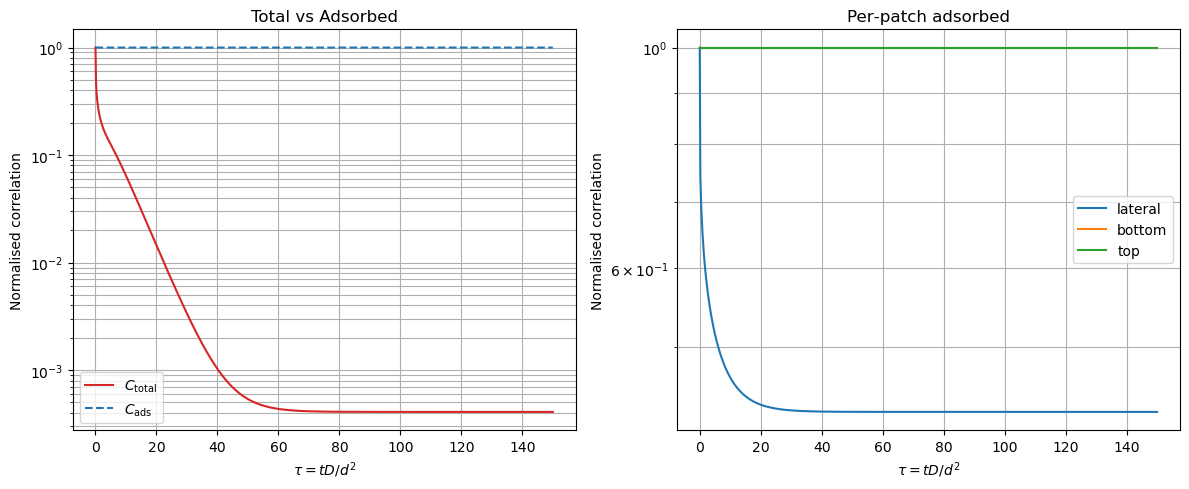

In [10]:
def sanitize_for_log(y, eps=1e-15):
    y = np.array(y, dtype=float)
    mask = np.isfinite(y) & (y > 0.0)
    if not np.any(mask):
        return np.full_like(y, np.nan)
    floor = max(eps, 1e-12 * np.nanmin(y[mask]))
    yc = y.copy()
    yc[~mask] = np.nan
    yc[yc <= 0] = floor
    return yc

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(tau, sanitize_for_log(C_total_t), label=r'$C_{\mathrm{total}}$', color='C3')
plt.plot(tau, sanitize_for_log(C_ads_t),   label=r'$C_{\mathrm{ads}}$',   color='C0', ls='--')
plt.yscale('log'); plt.grid(True, which='both')
plt.xlabel(r'$\tau = t D / d^2$'); plt.ylabel('Normalised correlation')
plt.title('Total vs Adsorbed'); plt.legend()

plt.subplot(1,2,2)
plt.plot(tau, sanitize_for_log(C_lat_t), label='lateral', color='C0')
plt.plot(tau, sanitize_for_log(C_bot_t), label='bottom',  color='C1')
plt.plot(tau, sanitize_for_log(C_top_t), label='top',     color='C2')
plt.yscale('log'); plt.grid(True, which='both')
plt.xlabel(r'$\tau = t D / d^2$'); plt.ylabel('Normalised correlation')
plt.title('Per‑patch adsorbed'); plt.legend()

plt.tight_layout(); plt.show()

## Harmonic measure convergence check

We compare the final accumulated $\overline{\omega}_t(s)$ to the harmonic measure $w(s)$ for each surface, normalised for shape.

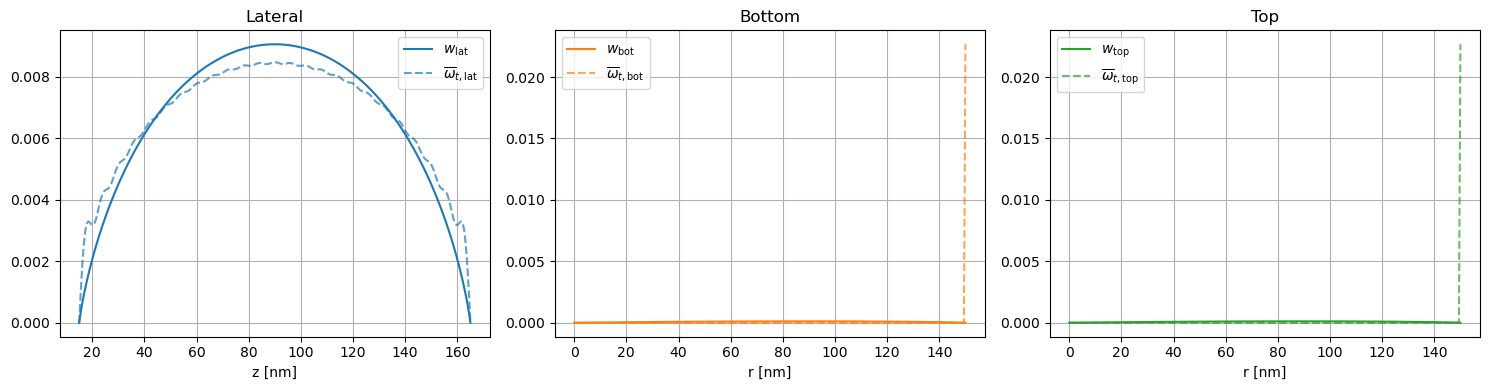

In [11]:
def norm_lat(f):
    A = np.trapezoid(f, z)
    return f / A if A != 0 else f

def norm_cap(f):
    A = np.trapezoid(f * r, r)
    return f / A if A != 0 else f

plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.plot(z, norm_lat(w_lat), label=r'$w_{\mathrm{lat}}$', color='C0')
plt.plot(z, norm_lat(omega_lat), '--', label=r'$\overline{\omega}_{t,\mathrm{lat}}$', color='C0', alpha=0.7)
plt.xlabel('z [nm]'); plt.title('Lateral'); plt.grid(True); plt.legend()

plt.subplot(1,3,2)
plt.plot(r, norm_cap(w_bot), label=r'$w_{\mathrm{bot}}$', color='C1')
plt.plot(r, norm_cap(omega_bot), '--', label=r'$\overline{\omega}_{t,\mathrm{bot}}$', color='C1', alpha=0.7)
plt.xlabel('r [nm]'); plt.title('Bottom'); plt.grid(True); plt.legend()

plt.subplot(1,3,3)
plt.plot(r, norm_cap(w_top), label=r'$w_{\mathrm{top}}$', color='C2')
plt.plot(r, norm_cap(omega_top), '--', label=r'$\overline{\omega}_{t,\mathrm{top}}$', color='C2', alpha=0.7)
plt.xlabel('r [nm]'); plt.title('Top'); plt.grid(True); plt.legend()

plt.tight_layout(); plt.show()

## Torsional rigidity

The torsional rigidity is:
$$
T = 4 \int_\Omega U(r,z) \, dV
$$
We also report the dimensionless $T / R^4$.

In [12]:
T_val = 4.0 * vol_int(U)
T_dimless = T_val / (R**4)
print(f"Torsional rigidity T = {T_val:.6e} [nm^4]")
print(f"Dimensionless T/R^4 = {T_dimless:.6e}")

Torsional rigidity T = 2.951677e+10 [nm^4]
Dimensionless T/R^4 = 5.830474e+01


## Summary table

In [13]:
summary = {
    "Quantity": [
        r"$G_{\mathrm{ads}}(\infty)$",
        r"$G_{\mathrm{lat}}(\infty)$",
        r"$G_{\mathrm{bot}}(\infty)$",
        r"$G_{\mathrm{top}}(\infty)$",
        r"$M(0)$",
        r"$M(t_{\mathrm{end}})$",
        r"$C_{\mathrm{total}}(t_{\mathrm{end}})$",
        r"$C_{\mathrm{ads}}(t_{\mathrm{end}})$",
        r"$T$ [nm$^4$]",
        r"$T / R^4$"
    ],
    "Value": [
        G_ads_inf, G_lat_inf, G_bot_inf, G_top_inf,
        G_bulk_t[0], G_bulk_t[-1],
        C_total_t[-1], C_ads_t[-1],
        T_val, T_dimless
    ]
}
df_summary = pd.DataFrame(summary)
df_summary

,Quantity,Value
0,$G_{\mathrm{ads}}(\infty)$,2.811507e-11
1,$G_{\mathrm{lat}}(\infty)$,6.891109e-15
2,$G_{\mathrm{bot}}(\infty)$,2.809798e-11
3,$G_{\mathrm{top}}(\infty)$,1.020263e-14
4,$M(0)$,9.609539e-12
5,$M(t_{\mathrm{end}})$,1.973716e-22
6,$C_{\mathrm{total}}(t_{\mathrm{end}})$,4.086176e-04
7,$C_{\mathrm{ads}}(t_{\mathrm{end}})$,9.998603e-01
8,$T$ [nm$^4$],2.951677e+10
9,$T / R^4$,5.830474e+01


[asymptotics] S(t) ~ 1 - 5.646e-02 √t on small-time window.
[spectrum] slowest decay rate (dimensionless) λ11 d^2 = 0.157


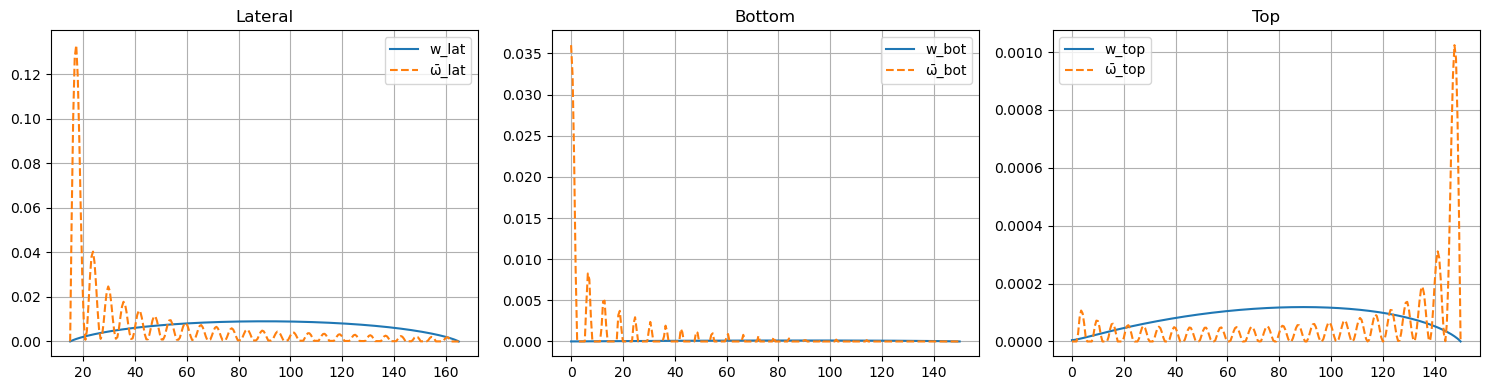

In [ ]:
# --- Diagnostics: early-time asymptotics and omega t  w shape checks ---

# 1) Early-time behaviour: survival S(t) = int Omega P dV ~ 1 - c \sqrt t
S_t = np.array([vol_int(Pbar_sov(t)) for t in times])
eps = 1e-12
mask_small = (times > 0) & (times < 0.01 * t_diff)
if np.any(mask_small):
    # Fit S(t) = 1 - a \sqrt t on the small-time window
    x = np.sqrt(times[mask_small])
    y = 1.0 - S_t[mask_small]
    a = np.dot(x, y) / np.dot(x, x)
    print(f"[asymptotics] S(t) ~ 1 - {a:.3e} $s\sqrt{t}$ on small-time window.")

# 2) Eigenvalue slope at intermediate times (slowest mode)
lam11 = lam[0,0]  # m=1, n=1 in 1-based; here it's [0,0] in 0-based
print(f"[spectrum] slowest decay rate (dimensionless) λ11 d2 = {lam11 * d**2:.3f}")

# 3) Shape comparison omega t vs w at a late time (normalised with correct surface measures)
def norm_lat(f):
    A = np.trapezoid(f, z)
    return f / A if A != 0 else f

def norm_cap(f):
    A = np.trapezoid(f * r, r)
    return f / A if A != 0 else f

# Recompute omega t at final time to be sure it's consistent with your latest settings
omega_lat_fin = np.zeros_like(z)
omega_bot_fin = np.zeros_like(r)
omega_top_fin = np.zeros_like(r)
j_lat_prev = j_bot_prev = j_top_prev = None
for i, t in enumerate(times):
    jl = j_lateral_sov(t); jb = j_bottom_sov(t); jt = j_top_sov(t)
    if i > 0:
        omega_lat_fin += 0.5 * (j_lat_prev + jl) * dt
        omega_bot_fin += 0.5 * (j_bot_prev + jb) * dt
        omega_top_fin += 0.5 * (j_top_prev + jt) * dt
    j_lat_prev, j_bot_prev, j_top_prev = jl, jb, jt

plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.plot(z, norm_lat(w_lat), label='w_lat'); plt.plot(z, norm_lat(omega_lat_fin), '--', label='ω̄_lat')
plt.title('Lateral'); plt.grid(True); plt.legend()

plt.subplot(1,3,2)
plt.plot(r, norm_cap(w_bot), label='w_bot'); plt.plot(r, norm_cap(omega_bot_fin), '--', label='ω̄_bot')
plt.title('Bottom'); plt.grid(True); plt.legend()

plt.subplot(1,3,3)
plt.plot(r, norm_cap(w_top), label='w_top'); plt.plot(r, norm_cap(omega_top_fin), '--', label='ω̄_top')
plt.title('Top'); plt.grid(True); plt.legend()
plt.tight_layout(); plt.show()